# PHAS0043 Coursework 2: Far-IR spectroscopy of AFGL 618

## General Information

### Target Overview
AFGL 618 is a carbon-rich protoplanetary nebula (PPN) that has recently
left the asymptotic giant branch (AGB) of its evolution and is quickly heading towards the planetary nebula (PN) phase. It is 1.1 $\pm$ 0.2 kpc from Earth and is an important source of data for understanding PN formation due to how recently it shifted from AGB to PPN.

### Data Used
The data used in this experiment is a fits file from the Herschel SPIRE-FTS instrument. It has the observation ID 1342191214 and is point-source calibrated. The observation occurred on 26/02/2010 and was a 38 minute exposure with a resolution of 1.1845 GHz.This information was extracted from the header of the fits file.

### Other information
Libraries used: numpy, matplotlib, astropy, scipy

## Experimental Outline
The experiment will follow the structure below, with further information on each step in markdown cells before the relevant code.

####  1: Extracting the Data
####  2: Removing the Continuum
####  3: Fitting the CO Ladder
####  4: Velocity Calculations
####  5: Movement of PN in Heliocentric Frame
####  6: Temperature Calculations
####  7: Conclusion


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from astropy.io import fits
from scipy import optimize
%matplotlib inline
# Import the necessary libraries

## Section 1: Extracting the Data

After downloading the data from the ESA archive, the first step is importing it into the notebook. This is done using astropy's FITS features in the cell below. The spectrum is then split up into lower frequency (Ldata, SLW) and higher frequency (Sdata, SSW) bands to account for the fact that these data are collected by different instruments. Finally, the raw data is plotted side by side with a HST image of AFGL 618 for reference.

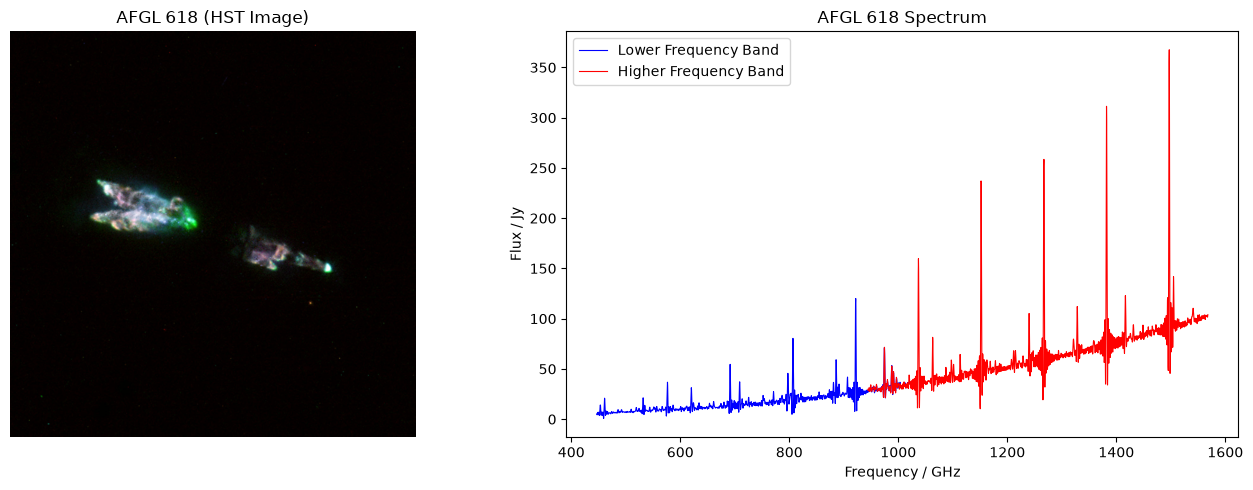

In [2]:
path = '/Users/Lucas/Desktop/Downloads/'
# Set the directory

fdata = fits.open('hspirespectrometer1342191214_a1060001_spg_HR_20spss_1461127169151.fits')
# Open the FITS file

Ldata = []
Ldata.append(fdata[5].data)
Lfr = Ldata[0].field(0)
Lsp = Ldata[0].field(1)
Ler = Ldata[0].field(2)
Sdata = []
Sdata.append(fdata[18].data)
Sfr = Sdata[0].field(0)
Ssp = Sdata[0].field(1)
Ser = Sdata[0].field(2)
# Extract the data from the FITS file in seperate arrays for the higher and lower bands

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
# Create a figure with two subplots

img = mpimg.imread('CRL 618.jpg')
ax1.imshow(img)
ax1.axis("off")
ax1.set_title("AFGL 618 (HST Image)")
# Plot the image of AFGL 618 on the first subplot

ax2.plot(Lfr, Lsp, color='blue', lw=0.8, label='Lower Frequency Band')
ax2.plot(Sfr, Ssp, color='red', lw=0.8, label='Higher Frequency Band')
ax2.set_xlabel("Frequency / GHz")
ax2.set_ylabel("Flux / Jy")
ax2.set_title("AFGL 618 Spectrum")
ax2.legend()
# Plot the spectrum of AFGL 618 on the second subplot


plt.tight_layout()
plt.show()

## Section 2: Removing the Continuum

With the data now extracted split into its respective bands I will now remove the continuum, the thermal emission from circumstellar which increases as the frequency does. I do this by plotting it to a power law:

$$I_\nu = \tau\left(\frac{\nu}{\nu_0}\right)^{\beta}$$

With $I_\nu$ the continuum intensity in Jy, $\nu$ the frequency in GHz, $\beta$ being the dimensionless continuum index, $\nu_0$ a constant which I set to 1000 GHz as this lies in the SSW and SLW overlap keeping the fits stable and $\tau$ the continuum flux density at frequency $\nu_0$ in Jy. The starting guesses for $\beta$ and $\tau$ are hard coded to give a close initial fit.

The following code cell contains the definition of a function to fit the data to the power law using $\beta$ = 2 and $\tau$ = 25 as initial estimates for the SLW data. Then I identified any points (typically molecular lines) which drift more than 5 Jy, a value chosen by eye through trial and error, from this initial continuum line and refit the power law using this new set of data, providing a continuum fit over only the continuum points. The raw SLW data and the initial curve with the outliers identified was then plot next to the corrected continuum power law. 


Fitted parameters: tau = 32.75 +/- 0.17 Jy, beta = 2.354 +/- 0.022


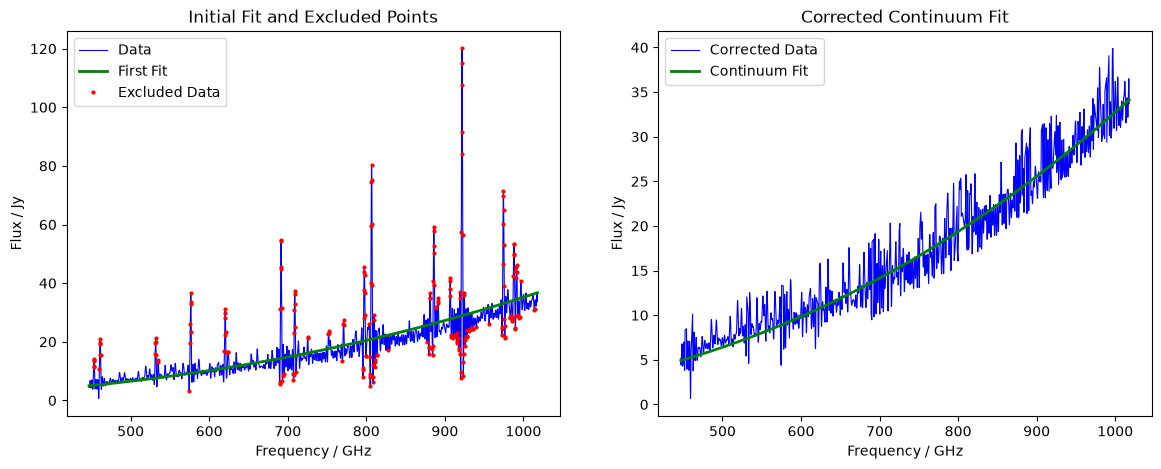

In [3]:
def continuum_fit(v, tau, beta, v0=1000):
    'Fit a power law to the continuum'
    return tau*(v/v0)**beta

p, cov = optimize.curve_fit(continuum_fit, Lfr, Lsp, sigma=Ler, p0=[25, 2])
model = continuum_fit(Lfr, *p)
# fit everything including lines to get a first estimate of the continuum

mask = np.abs(Lsp - model) <= 5
# Exclude points far from the first fit

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(Lfr, Lsp, color='blue', lw=0.8, label='Data')
ax1.plot(Lfr, model, color='green', lw=2, label='First Fit')
ax1.plot(Lfr[~mask], Lsp[~mask], 'r.', ms=4, label='Excluded Data')
ax1.set_xlabel("Frequency / GHz")
ax1.set_ylabel("Flux / Jy")
ax1.set_title("Initial Fit and Excluded Points")
ax1.legend()
# Plot the first fit and excluded points on the first subplot

p2, cov2 = optimize.curve_fit(continuum_fit, Lfr[mask], Lsp[mask], sigma=Ler[mask], p0=p)
continuum_model_norm = continuum_fit(Lfr, *p2)
# Refit on continuum points only


ax2.plot(Lfr[mask], Lsp[mask], color='blue', lw=0.8, label='Corrected Data')
ax2.plot(Lfr, continuum_model_norm, color='green', lw=2, label='Continuum Fit')
ax2.set_xlabel("Frequency / GHz")
ax2.set_ylabel("Flux / Jy")
ax2.set_title("Corrected Continuum Fit")
ax2.legend()
# Plot the continuum fit on the second subplot

tau_L, beta_L = p2
dtau_L, dbeta_L = np.sqrt(np.diag(cov2))
print(f'Fitted parameters: tau = {tau_L:.2f} +/- {dtau_L:.2f} Jy, beta = {beta_L:.3f} +/- {dbeta_L:.3f}')
# Find and print the fitted parameters and their uncertainties

Lsp_flat = Lsp - continuum_model_norm
# Subtract the continuum fit from the original spectrum

I then plot the continuum-subtracted spectrum for reference.

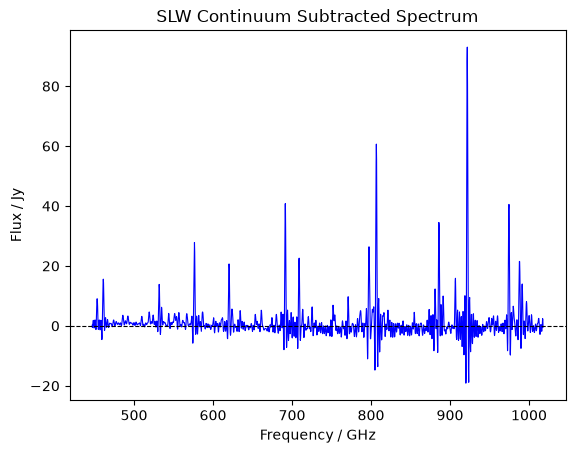

In [4]:
plt.plot(Lfr, Lsp_flat, color='blue', lw=0.8)
plt.xlabel('Frequency / GHz')
plt.ylabel('Flux / Jy')
plt.title('SLW Continuum Subtracted Spectrum')
plt.axhline(0, color='black', lw=0.8, ls='--')

This process is now repeated for the SSW data in the next two code cells.

Fitted parameters: tau = 33.35 +/- 0.12 Jy, beta = 2.506 +/- 0.011


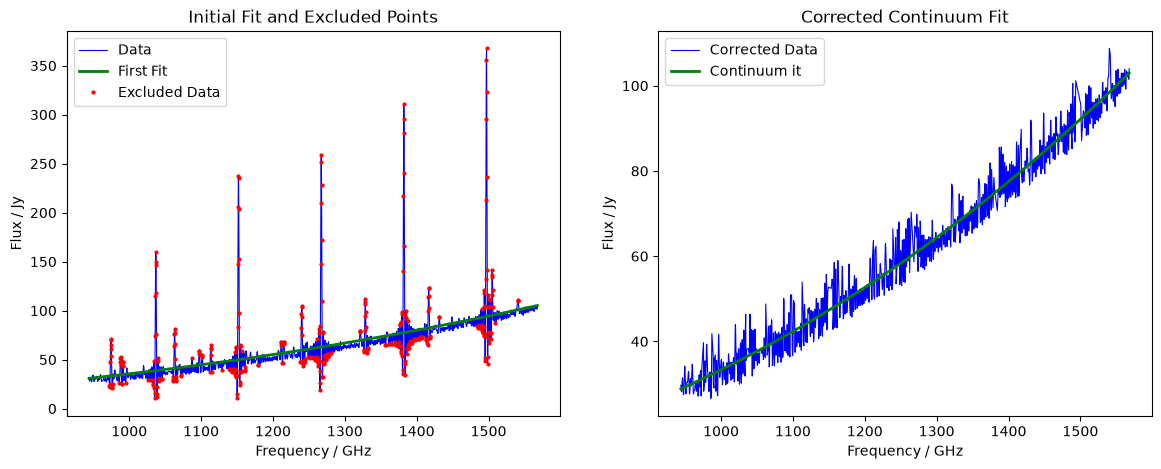

In [5]:
p, cov = optimize.curve_fit(continuum_fit, Sfr, Ssp, sigma=Ser, p0=[25, 2])
model = continuum_fit(Sfr, *p)
# fit everything including lines to get a first estimate of the continuum

mask = np.abs(Ssp - model) <= 8
# Exclude points far from the first fit

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(Sfr, Ssp, color='blue', lw=0.8, label='Data')
ax1.plot(Sfr, model, color='green', lw=2, label='First Fit')
ax1.plot(Sfr[~mask], Ssp[~mask], 'r.', ms=4, label='Excluded Data')
ax1.set_xlabel("Frequency / GHz")
ax1.set_ylabel("Flux / Jy")
ax1.set_title("Initial Fit and Excluded Points")
ax1.legend()
# Plot the first fit and excluded points on the first subplot

p2, cov2 = optimize.curve_fit(continuum_fit, Sfr[mask], Ssp[mask], sigma=Ser[mask], p0=p)
continuum_model_norm = continuum_fit(Sfr, *p2)
# Refit on continuum points only

ax2.plot(Sfr[mask], Ssp[mask], color='blue', lw=0.8, label='Corrected Data')
ax2.plot(Sfr, continuum_model_norm, color='green', lw=2, label='Continuum it')
ax2.set_xlabel("Frequency / GHz")
ax2.set_ylabel("Flux / Jy")
ax2.set_title("Corrected Continuum Fit")
ax2.legend()
# Plot the continuum fit on the second subplot

tau_S, beta_S = p2
dtau_S, dbeta_S = np.sqrt(np.diag(cov2))
print(f'Fitted parameters: tau = {tau_S:.2f} +/- {dtau_S:.2f} Jy, beta = {beta_S:.3f} +/- {dbeta_S:.3f}')
# Find and print the fitted parameters and their uncertainties

Ssp_flat = Ssp - continuum_model_norm
# Subtract the continuum fit from the original spectrum

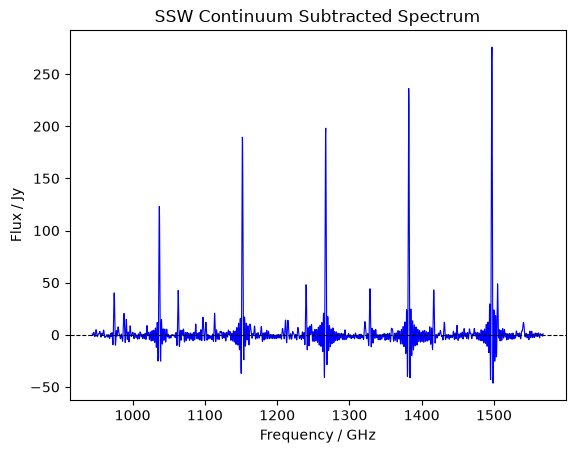

In [6]:
plt.plot(Sfr, Ssp_flat, color='blue', lw=0.8)
plt.xlabel('Frequency / GHz')
plt.ylabel('Flux / Jy')
plt.title('SSW Continuum Subtracted Spectrum')
plt.axhline(0, color='black', lw=0.8, ls='--')

I then plot the whole continuum-subtracted spectrum for use in the report.

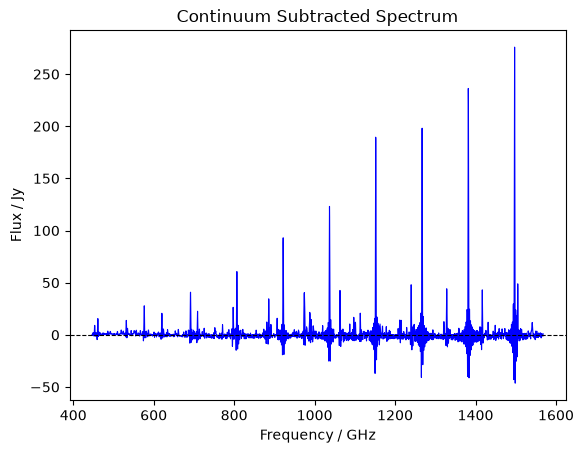

In [7]:
plt.plot(Sfr, Ssp_flat, color='blue', lw=0.8)
plt.plot(Lfr, Lsp_flat, color='blue', lw=0.8)
plt.xlabel('Frequency / GHz')
plt.ylabel('Flux / Jy')
plt.title('Continuum Subtracted Spectrum')
plt.axhline(0, color='black', lw=0.8, ls='--')

### Section 3 & 4: Line Fitting and Velocity Calculation

The next step of the project is to use a sinc function to calculate the instrument line function (ILF), the response of the instrument to the delta Dirac spectral line input, from the data using the following equation:
$$ ILF(v) = A \times \frac{sin(X)}{X} \\ \\
X = \frac{v - v_0}{w / \pi}$$

$A$ is the peak height in Jy, $\nu_0$ is the line centre in GHz and $w$ is the width in GHz.

I use a method of progressive subtraction, fitting the strongest line across the whole spectrum using the information in its window and then subtracted it from the spectrum repeated. After plotting all of the lines and finding their parameters, I realised that CO 10-9 seemed inaccurate. I found this was due to the presence of an overlapping HCN line, which I accounted for by removing before the progressive subtraction.

In the same loop which fitted the lines I also calculate their LSR velocities. I used the difference between my calculated value and my experimental value for the centre of each line to calculate its relative velocity shift. The equation for this is:

$${v} = {v}_{rest}\big(\frac{1}{1+\frac{v}{c}}\big)$$

I converted this into the usable form:

$$v = c\,\frac{\nu_{\rm rest} - \nu_0}{\nu_{\rm rest}}, \qquad \sigma_v = \frac{c\,\sigma_{\nu_0}}{\nu_{\rm rest}}$$



In the cell below, I plot the corrected spectra with the relevant CO lines identified. 

Text(0, 0.5, 'Flux / Jy')

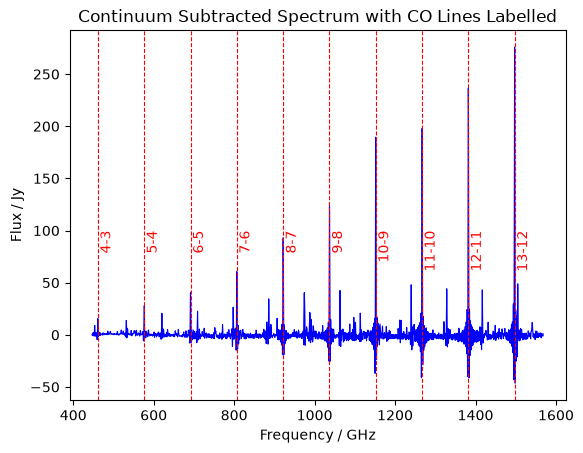

In [8]:
plt.plot(Lfr, Lsp_flat, color='blue', lw=0.8)
plt.plot(Sfr, Ssp_flat, color='blue', lw=0.8)

CO_lines = {'4-3': 461.041, '5-4': 576.268, '6-5': 691.473, '7-6': 806.652, '8-7': 921.800,'9-8': 1036.912, '10-9': 1151.985, '11-10': 1267.014, '12-11': 1381.995, '13-12': 1496.923}
Rest_lines_L = ['4-3', '5-4', '6-5', '7-6', '8-7']
Rest_lines_S = ['9-8', '10-9', '11-10', '12-11', '13-12']
# Set the rest lines into two separate lists for the lower and higher frequency bands

for line in CO_lines:
    plt.axvline(CO_lines[line], color='red', lw=0.8, ls='--')
    plt.text(CO_lines[line]+5, 100, line, rotation=90, verticalalignment='top', color='red')

plt.title('Continuum Subtracted Spectrum with CO Lines Labelled')
plt.xlabel('Frequency / GHz')
plt.ylabel('Flux / Jy')


The next plot details the removal of the HCN 13-12 line from the spectrum to make the CO 10-9 line more accurate. This was done after inspecting the data the CO line fitting originally produced. I did this by measuring the HCN lines on either side of HCN 13-12 and averaging their heights and widths in order to give me an estimate for line fitting.

My method for plotting sinc functions and the AI brief will be covered in the next markdown cell.

v0_HCN_13_12: 1151.566973942387
A_HCN_13_12: 46.252065788651834
w_HCN_13_12: 1.1569851168425829


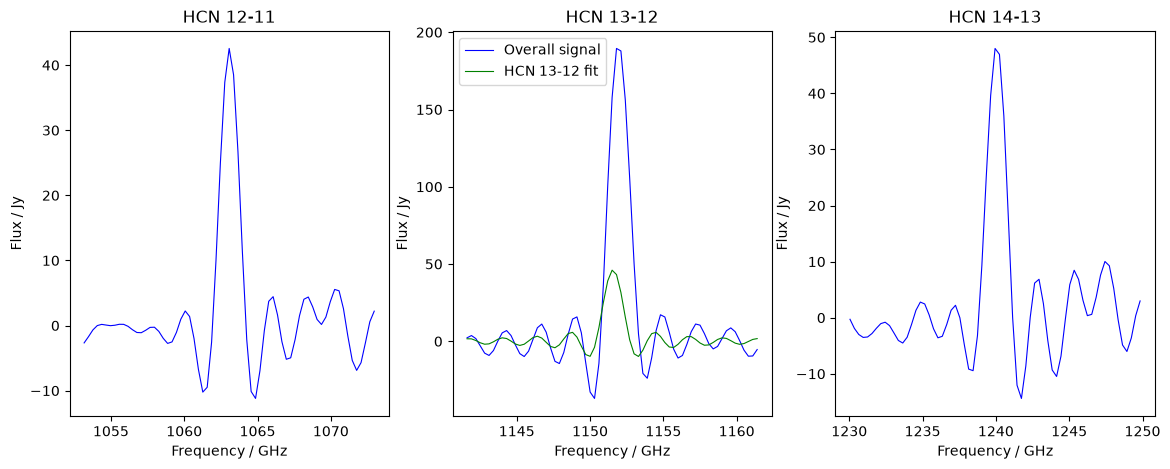

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
ax1 = axes[0]
ax2 = axes[1]
ax3 = axes[2]

def ilf(v, A, v0, w):
    'Sinc function for instrumental line shape'
    X = (v - v0) / (w / np.pi)
    return A * (np.sin(X) / X)

HCN_lines = {"12-11": 1062.9881, "13-12": 1151.4524, "14-13": 1239.8903}
# Define the HCN lines of interest

mask = np.where((Sfr > HCN_lines["12-11"] -10) & (Sfr < HCN_lines["12-11"] + 10))
# Create a mask to select data points around the HCN 12-11 line

Sfr_masked = Sfr[mask]
Ssp_masked = Ssp_flat[mask]

ax1.plot(Sfr_masked, Ssp_masked, color='blue', lw=0.8)
ax1.set_xlabel('Frequency / GHz')
ax1.set_ylabel('Flux / Jy')
# Plot the masked data around the HCN 12-11 line on the first subplot

mask_13_12 = np.where((Sfr > HCN_lines["13-12"] -10) & (Sfr < HCN_lines["13-12"] + 10))

Sfr_masked_13_12 = Sfr[mask_13_12]
Ssp_masked_13_12 = Ssp_flat[mask_13_12]

ax2.plot(Sfr_masked_13_12, Ssp_masked_13_12, color='blue', lw=0.8, label='Overall signal')
ax2.set_xlabel('Frequency / GHz')
ax2.set_ylabel('Flux / Jy')

mask = np.where((Sfr > HCN_lines["14-13"] -10) & (Sfr < HCN_lines["14-13"] + 10))

Sfr_masked = Sfr[mask]
Ssp_masked = Ssp_flat[mask]

ax3.plot(Sfr_masked, Ssp_masked, color='blue', lw=0.8)
ax3.set_xlabel('Frequency / GHz')
ax3.set_ylabel('Flux / Jy')
ax1.set_xlabel('Frequency / GHz')
ax1.set_ylabel('Flux / Jy')

def fit_lines_HCN(fr, flat, lines, noise):
    'Fit the HCN lines in the spectrum'
    copy = flat.copy()
    lines = sorted(lines, key=lambda n: copy[np.abs(fr - HCN_lines[n]) < 1].max(), reverse=True)
    results = {}
    for n in lines:
        window = np.abs(fr - HCN_lines[n]) < 5
        x, y = fr[window], copy[window]
        guess = [y.max(), HCN_lines[n], 1.2]
        p, cov = optimize.curve_fit(ilf, x, y, p0=guess)

        residual = y - ilf(x, *p)
        chi2 = np.sum((residual / noise) ** 2)
        chi2_red = chi2 / (len(x) - 3)

        results[n] = (p, np.sqrt(np.diag(cov)), chi2_red)
        copy = copy - ilf(fr, *p)
    return results, copy

mask_L = np.abs(Lsp_flat) <= 4
mask_S = np.abs(Ssp_flat) <= 8
noise_L = np.std(Lsp_flat[mask_L])
noise_S = np.std(Ssp_flat[mask_S])

HCN_results, HCN_surrogate = fit_lines_HCN(Sfr, Ssp_flat, HCN_lines, noise_S)

shift = 0.5 * ((HCN_results['12-11'][0][1] - HCN_lines['12-11']) / HCN_lines['12-11'] + (HCN_results['14-13'][0][1] - HCN_lines['14-13']) / HCN_lines['14-13'])
v0_HCN_13_12 = HCN_lines['13-12'] * (1 + shift)


A_HCN_13_12 = (HCN_results["12-11"][0][0] + HCN_results['14-13'][0][0]) / 2
w_HCN_13_12 = (HCN_results["12-11"][0][2] + HCN_results['14-13'][0][2]) / 2

print

print(f'v0_HCN_13_12: {v0_HCN_13_12}')
print(f'A_HCN_13_12: {A_HCN_13_12}')
print(f'w_HCN_13_12: {w_HCN_13_12}')

HCN_13_12_fit = ilf(Sfr, A_HCN_13_12, v0_HCN_13_12, w_HCN_13_12)

ax2.plot(Sfr_masked_13_12, HCN_13_12_fit[mask_13_12], color='green', lw=0.8, label='HCN 13-12 fit')

ax1.set_title('HCN 12-11')
ax2.set_title('HCN 13-12')
ax3.set_title('HCN 14-13')
ax2.legend()

Ssp_corr_HCN = Ssp_flat - HCN_13_12_fit


In the next cell I plot out the original continuum-subtracted spectrum next to the version with HCN to inspect visually how it changes.

Text(0.5, 1.0, 'SSW Continuum Subtracted Spectrum (HCN 13-12 Uncorrected)')

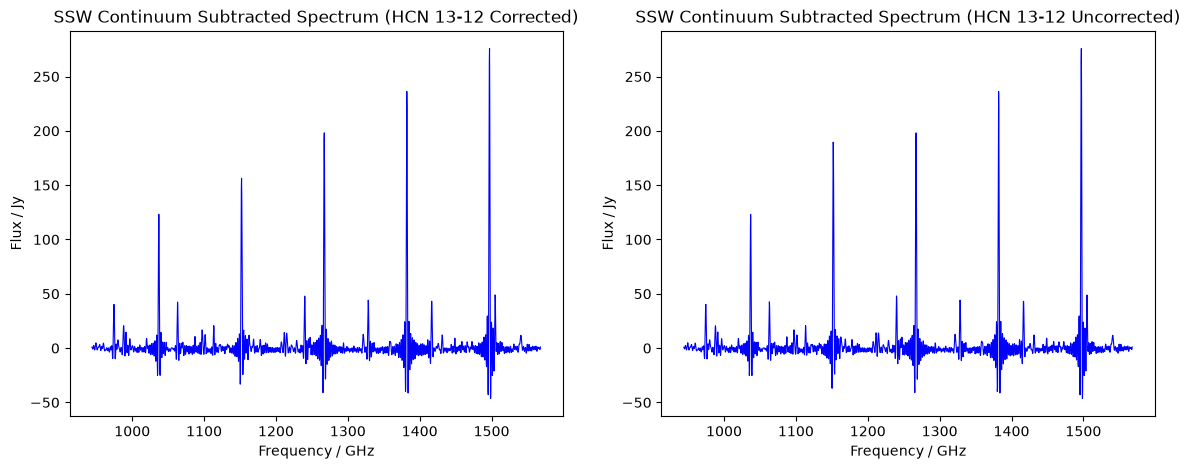

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(Sfr, Ssp_corr_HCN, color='blue', lw=0.8)
ax2.plot(Sfr, Ssp_flat, color='blue', lw=0.8)
ax1.set_xlabel('Frequency / GHz')
ax1.set_ylabel('Flux / Jy')
ax2.set_xlabel('Frequency / GHz')
ax2.set_ylabel('Flux / Jy')
ax1.set_title('SSW Continuum Subtracted Spectrum (HCN 13-12 Corrected)')
ax2.set_title('SSW Continuum Subtracted Spectrum (HCN 13-12 Uncorrected)')

In the next cell I fit sinc functions to the CO lines within a window, expand them out across the spectrum and then subtract them to form a surrogate data set. I do this starting from the highest amplitude line to the lowest. The goodness of each fit is found using the noise in the continuum according to:

$$\chi^2 = \sum_i \left(\frac{y_i - \mathrm{ILF}(\nu_i)}{\sigma}\right)^{2}, \qquad
\chi^2_{\rm red} = \frac{\chi^2}{N-3}$$
Where the residual of each point is divided by the noise of the SSW or SLW spectrum to give $\chi^2$.


In [11]:
def fit_lines(fr, flat, lines, noise):
    'Fit the CO lines in the spectrum'
    copy = flat.copy()
    # Create a copy of the flat spectrum to avoid modifying the original data
    lines = sorted(lines, key=lambda n: copy[np.abs(fr - CO_lines[n]) < 1].max(), reverse=True)
    # Sort the lines by flux starting with the strongest
    results = {}
    for n in lines:
        'Create a loop to fit each line in the list of lines'
        window = np.abs(fr - CO_lines[n]) < 5
        # Select a window of data points around the line to fit
        x, y = fr[window], copy[window]
        # Take the frequency and flux values within the window
        guess = [y.max(), CO_lines[n], 1.2]
        # Make an initial guess for the fit parameters: amplitude, center frequency, and width
        p, cov = optimize.curve_fit(ilf, x, y, p0=guess)
        # Fit the line

        residual = y - ilf(x, *p)
        chi2 = np.sum((residual / noise) ** 2)
        chi2_red = chi2 / (len(x) - 3)
        # Calculate the residuals and chi-squared values for the fit


        results[n] = (p, np.sqrt(np.diag(cov)), chi2_red)
        # Store the fit parameters, uncertainties, and reduced chi-squared value in the results variable
        copy = copy - ilf(fr, *p)
        # Subtract the line from the copy
    return results, copy

mask_L = np.abs(Lsp_flat) <= 4
mask_S = np.abs(Ssp_flat) <= 8
noise_L = np.std(Lsp_flat[mask_L])
noise_S = np.std(Ssp_flat[mask_S])
print(f'Noise in L band: {noise_L:.3f} Jy')
print(f'Noise in S band: {noise_S:.3f} Jy')
# Find the noise in the L and S bands


L_results, L_surrogate = fit_lines(Lfr, Lsp_flat, Rest_lines_L, noise_L)
S_results, S_surrogate = fit_lines(Sfr, Ssp_corr_HCN, Rest_lines_S, noise_S)

c = 299792.458
all_results = {**L_results, **S_results}
vels, dvels = [], []

print('Line   Rest (GHz)  Centre (GHz)        Height (Jy)    Width (GHz)       Velocity (km/s)   Chi^2_red')
for n in Rest_lines_L + Rest_lines_S:
    A, v0, w = all_results[n][0]
    dA, dv0, dw = all_results[n][1]
    chi2_red = all_results[n][2]
    vel = c * ((CO_lines[n] - v0) / CO_lines[n])
    dvel = c * dv0 / CO_lines[n]
    vels.append(vel)
    dvels.append(dvel)
    print(f'{n:6} {CO_lines[n]:9.3f}  {v0:9.3f} +/- {dv0:.3f}   {A:6.1f} +/- {dA:4.1f}   '
          f'{w:.3f} +/- {dw:.3f}   {vel:6.1f} +/- {dvel:4.1f}   {chi2_red:.2f}')
# Plot the table of results

Noise in L band: 1.700 Jy
Noise in S band: 3.170 Jy
Line   Rest (GHz)  Centre (GHz)        Height (Jy)    Width (GHz)       Velocity (km/s)   Chi^2_red
4-3      461.041    461.067 +/- 0.019     15.8 +/-  0.5   1.181 +/- 0.016    -16.6 +/- 12.3   0.27
5-4      576.268    576.379 +/- 0.026     25.4 +/-  1.0   1.251 +/- 0.024    -57.7 +/- 13.7   1.24
6-5      691.473    691.468 +/- 0.011     40.7 +/-  0.7   1.169 +/- 0.010      2.3 +/-  5.0   0.66
7-6      806.652    806.727 +/- 0.022     60.6 +/-  2.0   1.234 +/- 0.020    -27.7 +/-  8.1   4.97
8-7      921.800    921.849 +/- 0.007     93.8 +/-  1.0   1.197 +/- 0.006    -16.1 +/-  2.4   1.38
9-8     1036.912   1036.991 +/- 0.005    123.3 +/-  1.0   1.201 +/- 0.005    -22.9 +/-  1.5   0.36
10-9    1151.985   1152.085 +/- 0.013    158.1 +/-  3.1   1.233 +/- 0.012    -26.1 +/-  3.4   3.59
11-10   1267.014   1267.126 +/- 0.010    200.0 +/-  2.9   1.209 +/- 0.008    -26.6 +/-  2.3   3.08
12-11   1381.995   1382.092 +/- 0.008    235.9 +/-  2.8 

In the next cell I simply plot out each of the fits next to the raw data and plot the residuals below it.

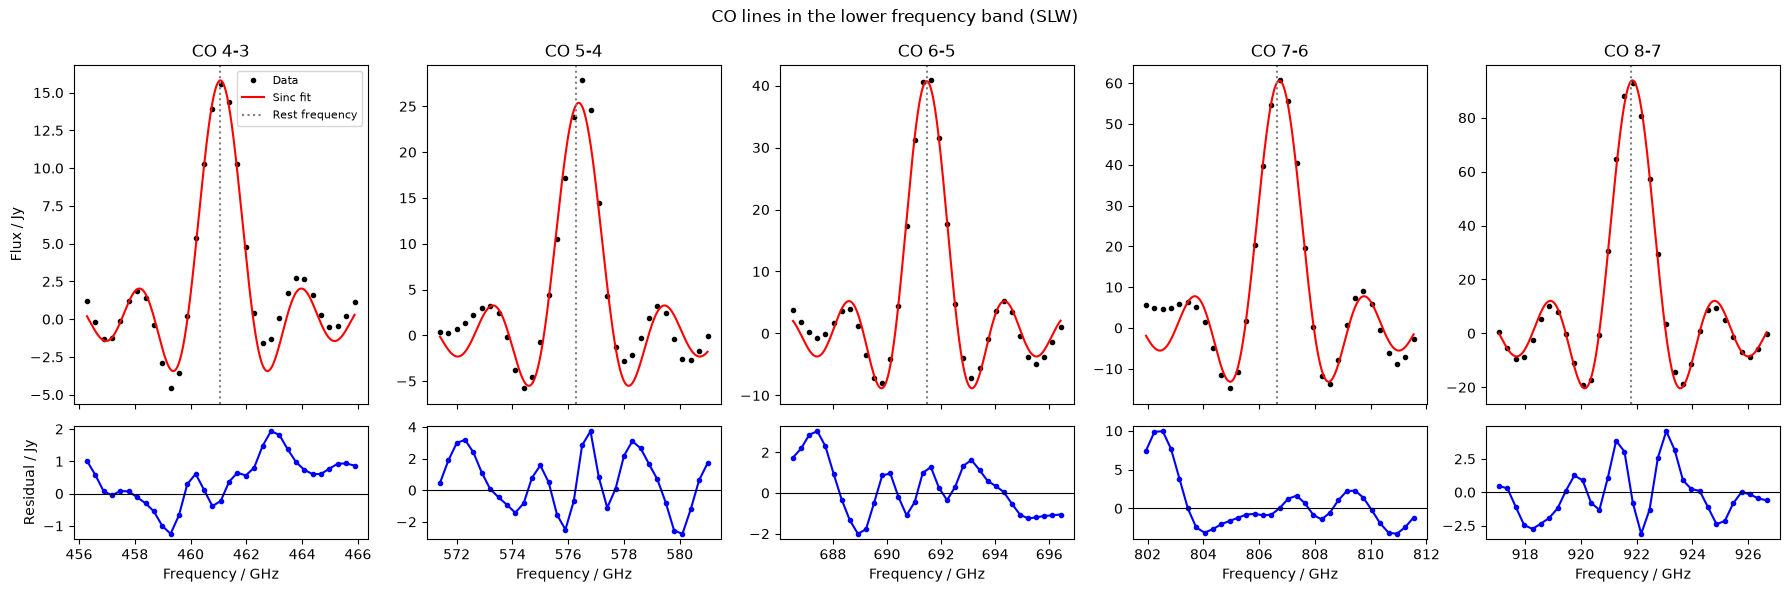

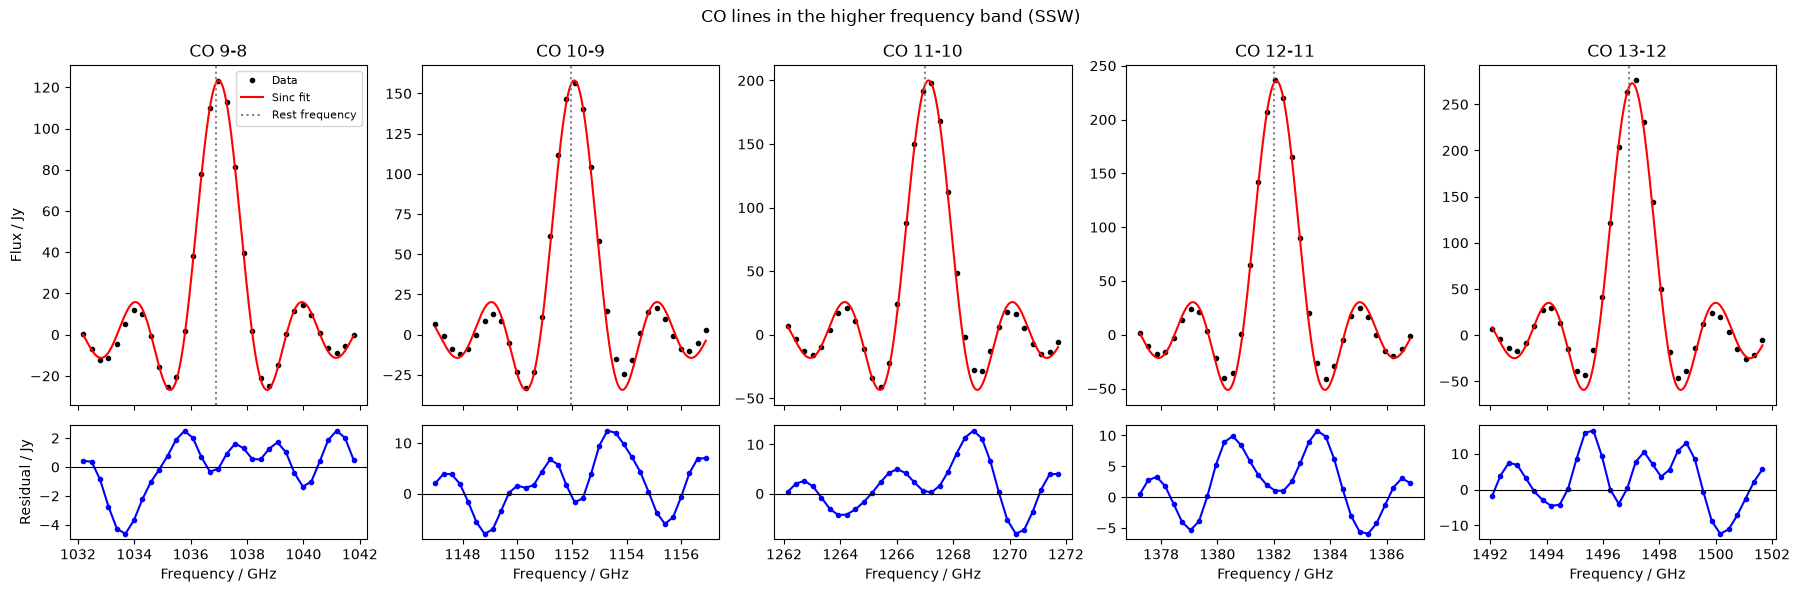

In [12]:
def plot_band(fr, flat, lines, title):
    fig, axes = plt.subplots(2, len(lines), figsize=(18, 6),
                             gridspec_kw={'height_ratios': [3, 1]}, sharex='col')

    for i, n in enumerate(lines):
        p = all_results[n][0]
        window = np.abs(fr - CO_lines[n]) < 5
        x = fr[window]
        y = flat[window]
        x_smooth = np.linspace(x.min(), x.max(), 500)

        # plot the data and the fit in the top row
        top = axes[0, i]
        top.plot(x, y, 'k.', label='Data')
        top.plot(x_smooth, ilf(x_smooth, *p), 'r-', label='Sinc fit')
        top.axvline(CO_lines[n], color='grey', ls=':', label='Rest frequency')
        top.set_title(f'CO {n}')

        # plot the residuals in the bottom row
        bottom = axes[1, i]
        bottom.plot(x, y - ilf(x, *p), 'b.-')
        bottom.axhline(0, color='black', lw=0.8)
        bottom.set_xlabel('Frequency / GHz')

    axes[0, 0].set_ylabel('Flux / Jy')
    axes[1, 0].set_ylabel('Residual / Jy')
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_band(Lfr, Lsp_flat, Rest_lines_L, 'CO lines in the lower frequency band (SLW)')
plot_band(Sfr, Ssp_corr_HCN, Rest_lines_S, 'CO lines in the higher frequency band (SSW)')

Next I will plot the spectrum with the CO lines removed to inspect any smaller lines:

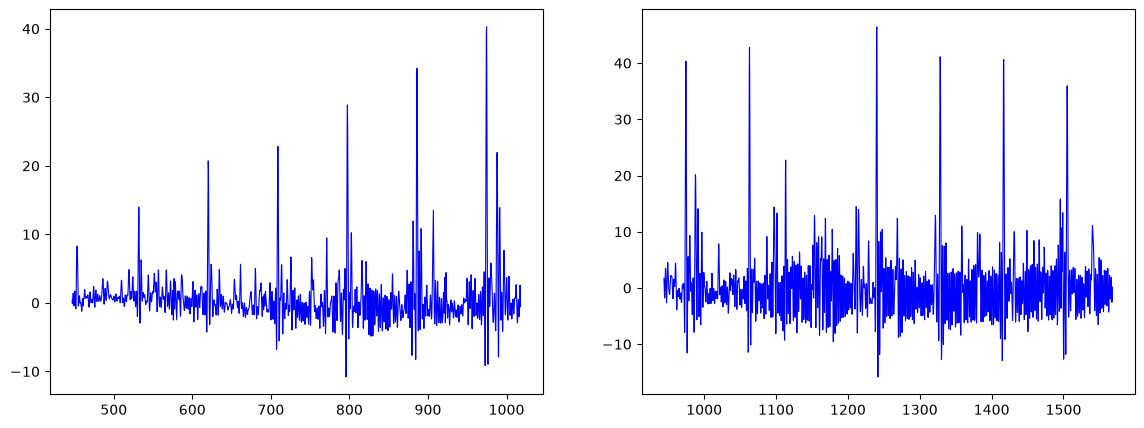

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(Lfr, L_surrogate, color='blue', lw=0.8)
ax2.plot(Sfr, S_surrogate, color='blue', lw=0.8)

### Section 5: Estimating the Relative Motion of the Star and PN w.r.t. the Heliocentric Reference Frame

I now convert the velocity of the star into the heliocentric frame of reference.

The first step is identifying the frame of the PN using the information in the header, then calculating how much of the Sun's angular velocity acts towards the nebula. 

$$\cos\theta = \sin\delta \, \sin\delta_\odot + \cos\delta \, \cos\delta_\odot \, \cos(\alpha - \alpha_\odot)$$

I use the fact that in the LSR frame of reference the sun moves at velocity $v_\odot = 20~\mathrm{km\,s^{-1}}$ towards RA and Dec $\alpha_\odot = 270.96^\circ$ and $\delta_\odot = +30.00^\circ$

In [14]:
print(fdata[0].header['RA'], fdata[0].header['DEC'])
# Print the RA and DEC of the source from the FITS header

vels = np.array(vels)
dvels = np.array(dvels)

sun_ra = np.radians(270.96)
sun_dec = np.radians(30.00)
sun_v = 20.0
# Define the Sun's RA, DEC, and velocity

PN_ra, PN_dec = np.radians(fdata[0].header['RA']), np.radians(fdata[0].header['DEC'])
# Calculate the RA and DEC of the source in radians

weights = 1 / dvels**2
mean_v = np.sum(weights * vels) / np.sum(weights)
mean_v_err = 1 / np.sqrt(np.sum(weights))
chi2_red = np.sum(((vels - mean_v) / dvels)**2) / (len(vels) - 1)
mean_v_err = mean_v_err * np.sqrt(chi2_red)
# Calculate the weighted mean velocity and its uncertainty

cos_theta = np.sin(PN_dec) * np.sin(sun_dec) + np.cos(PN_dec) * np.cos(sun_dec) * np.cos(PN_ra - sun_ra)
print(f'the angle theta is: {np.degrees(np.arccos(cos_theta)):3.1f} degrees')
# Calculate the angle between the Sun and the source

v_sun_los = sun_v * cos_theta
v_helio = mean_v - v_sun_los

print(f'cos(theta) = {cos_theta:.3f}, solar correction = {v_sun_los:.2f} km/s')
print(f'v_LSR = {mean_v:.1f} +/- {mean_v_err:.1f} km/s  ->  v_helio = {v_helio:.1f} +/- {mean_v_err:.1f} km/s')

70.72311706082505 36.11438358681009
the angle theta is: 111.2 degrees
cos(theta) = -0.362, solar correction = -7.23 km/s
v_LSR = -21.9 +/- 1.8 km/s  ->  v_helio = -14.7 +/- 1.8 km/s


### Step 6: Estimating the Rotational Temperature of the CO Gas

I will be using the following equation to plot how the flux is related to the temperature:

$$\ln\Bigg(\frac{4\pi F_{ji}}{A_{ji}hvg_j}\Bigg) = \ln\Bigg(\frac{N_0}{\Phi(T)d^2}\Bigg) - \frac{E_j}{kT}$$

Where: $F_{ul}$ is the integrated flux from upper level u to lower level l, $A_{ul}$ is the Einstein emission coefficient, $g_u$ is the statistical weight of the upper level, $E_u$ is the energy of the upper level, $\Phi(T)$ is the partition function and $d$ is the distance to the source. Plotting the left side of the equation against $E_u/k$ gives a straight line with a slope -1/T.

In the cell below I first find the integrated flux at each point, then plot a rough fit according to the above equation and use this to calculate the temperature. I propagated the error using the fact that the in ln(F) is the fractional error in F.

The temperature of CO is: 193.21 +- 1.46 K
The reduced chi-squared is: 174.72


Text(0.5, 1.0, 'Single-Temperature Fit for CO')

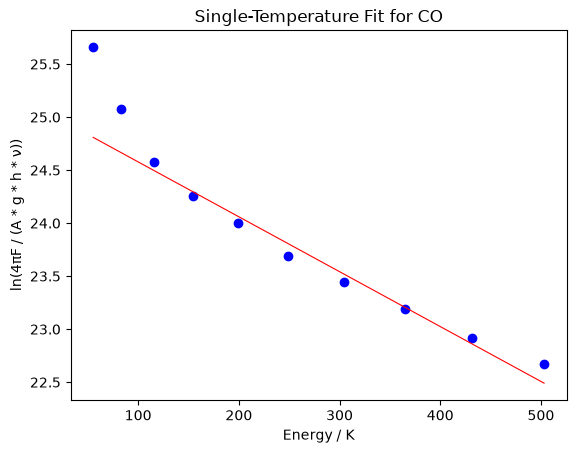

In [15]:
F = []
dF = []
v = []
dv = []

for n in Rest_lines_L + Rest_lines_S:
    'Calculate the integrated flux and its uncertainty for each CO line'
    A, v0, w = all_results[n][0]
    dA, dv0, dw = all_results[n][1]
    F.append(A * w * 1e-17)
    dF.append(dA * w * 1e-17)
    # Integrated flux of a sinc = height x width, converted from Jy GHz to W m^-2
    v.append((v0 * 1e9))
    # Convert GHz to Hz
    dv.append((dv0))


Einstein_As   = [6.126e-06, 1.221e-05, 2.137e-05, 3.422e-05, 5.134e-05, 7.330e-05, 1.006e-04, 1.339e-04, 1.735e-04, 2.200e-4]
Energies = [55.32, 82.97, 116.16, 154.87, 199.11, 248.88, 304.16, 364.97, 431.29, 503.13]
Weights = [9, 11, 13, 15, 17, 19, 21, 23, 25, 27]
k = 1.380649e-23
h = 6.62607015e-34
# Define constants

F = np.array(F)
dF = np.array(dF)
# convert the lists to numpy arrays for easier manipulation

def boltzmann(F, v, Einstein_As, Weights):
    'Carry out the boltzmann analysis to determine the rotational temperature'
    return(np.log((4*np.pi*F)/(Einstein_As*Weights*h*v)))

x = []

for i in range(len(Energies)):
    x.append(Energies[i])

y = []

for i in range(len(F)):
    y.append(boltzmann(F[i], v[i], Einstein_As[i], Weights[i]))
# Calculate the x and y values for the plot

y = np.array(y)
dy = dF / F
# Error in ln(F) is the fractional error in F

plt.plot(x, y, 'o', color='blue', label='')

temp_fit, temp_cov = np.polyfit(x, y, 1, w=1/dy, cov = 'unscaled')
# Fit a straight line to the data using weighted least squares

T = -1 / temp_fit[0]
dT = np.sqrt(temp_cov[0,0]) / temp_fit[0]**2
# Find the temperature and its uncertainty from the slope of the fitted line

plt.plot(x, np.polyval(temp_fit, x), color='red', lw=0.8, label='Fit')
print(f'The temperature of CO is: {T:.2f} +- {dT:.2f} K')
plt.xlabel('Energy / K')
plt.ylabel('ln(4πF / (A * g * h * ν))')

chi2_red = np.sum(((y - np.polyval(temp_fit, x)) / dy)**2) / (len(x) - 2)
print(f'The reduced chi-squared is: {chi2_red:.2f}')
plt.title('Single-Temperature Fit for CO')
# Calculate the reduced chi-squared value and plot the final results

The high value of $\chi^2_{red}$ shows that the assumption of a linear fit is incorrect and doesn't match the error. 

This suggests more than one temperatures, so in the cell below I used the same method as above and plotted the J = 4-3 to 7-6 separately to 8-7 to 13-12 and found two different temperatures.

The temperature of CO from J=4-3 to J=7-6 is: 68.01 +- 1.89 K, reduced chi-squared = 33.32
The temperature of CO from J=8-7 to J=13-12 is: 230.27 +- 2.55 K, reduced chi-squared = 16.59


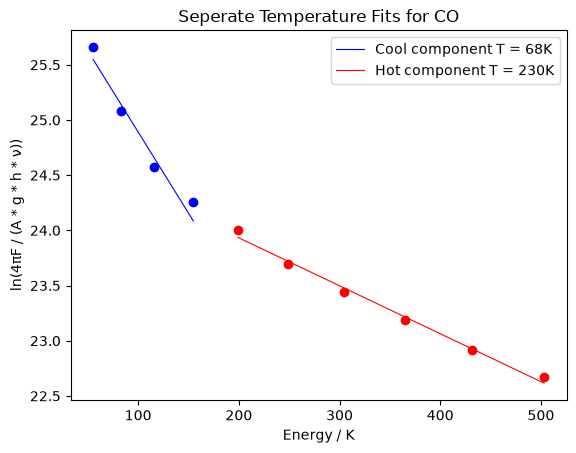

In [16]:
T1_y = y[0:4]
T1_x = x[0:4]
T1_dy = dy[0:4]

T2_y = y[4:10]
T2_x = x[4:10]
T2_dy = dy[4:10]



plt.plot(T1_x, T1_y, 'o', color='blue')
plt.plot(T2_x, T2_y, 'o', color='red')

temp_fit1, temp_cov1 = np.polyfit(T1_x, T1_y, 1, w=1/T1_dy, cov = 'unscaled')
temp_fit2, temp_cov2 = np.polyfit(T2_x, T2_y, 1, w=1/T2_dy, cov = 'unscaled')

plt.plot(T1_x, np.polyval(temp_fit1, T1_x), color='blue', lw=0.8, label='Cool component T = 68K')
plt.plot(T2_x, np.polyval(temp_fit2, T2_x), color='red', lw=0.8, label='Hot component T = 230K')

T_1 = -1 / temp_fit1[0]
dT_1 = np.sqrt(temp_cov1[0,0]) / temp_fit1[0]**2
chi2_red1 = np.sum(((T1_y - np.polyval(temp_fit1, T1_x)) / T1_dy)**2) / (len(T1_x) - 2)
T_2 = -1 / temp_fit2[0] 
dT_2 = np.sqrt(temp_cov2[0,0]) / temp_fit2[0]**2
chi2_red2 = np.sum(((T2_y - np.polyval(temp_fit2, T2_x)) / T2_dy)**2) / (len(T2_x) - 2)

print(f'The temperature of CO from J=4-3 to J=7-6 is: {T_1:.2f} +- {dT_1:.2f} K, reduced chi-squared = {chi2_red1:.2f}')
print(f'The temperature of CO from J=8-7 to J=13-12 is: {T_2:.2f} +- {dT_2:.2f} K, reduced chi-squared = {chi2_red2:.2f}')
plt.xlabel('Energy / K')
plt.ylabel('ln(4πF / (A * g * h * ν))')
plt.title('Seperate Temperature Fits for CO')
plt.legend()


The fits visually fit the data more accurately howeber the values of $chi^2$ are still relatively high, so I will attempt to correct this by plotting a temperature curve using the estimated values of T as starting parameters. The equation of this curve is:

$$Y_u = \ln\!\left(a_1\,e^{-E_u/kT_1} + a_2\,e^{-E_u/kT_2}\right)$$

A similar method as before is used to refine the guess and give a more accurate fit.

Cool component: T1 = 34 +/- 4 K
Hot component:  T2 = 240 +/- 9 K
Reduced chi-squared = 6.7


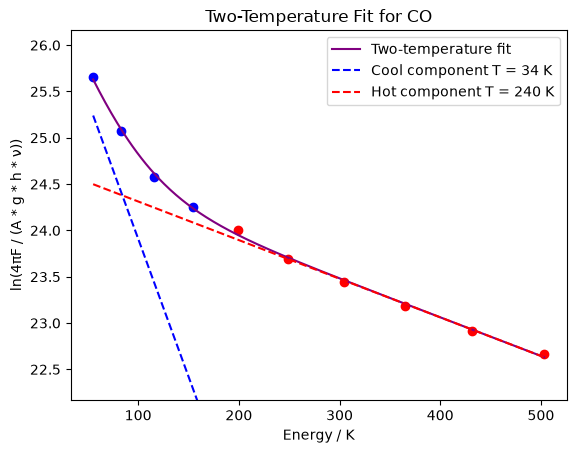

In [17]:
x = np.array(x)
x_smooth = np.linspace(x.min(), x.max(), 300)

def two_temp(E, a1, T1, a2, T2):
    'Rotation diagram for two gas components at temperatures T1 and T2'
    return np.log(np.exp(a1 - E / T1) + np.exp(a2 - E / T2))

plt.plot(T1_x, T1_y, 'o', color='blue')
plt.plot(T2_x, T2_y, 'o', color='red')

guess = [temp_fit1[1], T_1, temp_fit2[1], T_2]
# Start from the two straight-line fit's intercepts and temperatures

curve_par, curve_cov = optimize.curve_fit(two_temp, x, y, p0=guess, sigma=dy, maxfev=10000)
curve_err = np.sqrt(np.diag(curve_cov))
# Fit all ten lines at once, each weighted by its error

a1, T1_curve, a2, T2_curve = curve_par
dT1_curve, dT2_curve = curve_err[1], curve_err[3]

chi2_red_curve = np.sum(((y - two_temp(x, *curve_par)) / dy)**2) / (len(x) - 4)
# 4 fitted parameters, so N - 4 degrees of freedom

print(f'Cool component: T1 = {T1_curve:.0f} +/- {dT1_curve:.0f} K')
print(f'Hot component:  T2 = {T2_curve:.0f} +/- {dT2_curve:.0f} K')
print(f'Reduced chi-squared = {chi2_red_curve:.1f}')
# Print the results of the two-temperature fit

x = np.array(x)
x_smooth = np.linspace(x.min(), x.max(), 300)
plt.xlabel('Energy / K')
plt.ylabel('ln(4πF / (A * g * h * ν))')
# Plot the two-temperature fit results


plt.plot(x_smooth, two_temp(x_smooth, *curve_par), color='purple', label='Two-temperature fit')
plt.plot(x_smooth, a1 - x_smooth / T1_curve, color='blue', ls='--', label=f'Cool component T = 34 K')
plt.plot(x_smooth, a2 - x_smooth / T2_curve, color='red', ls='--', label=f'Hot component T = 240 K')
plt.ylim(min(y) - 0.5, max(y) + 0.5)
plt.title('Two-Temperature Fit for CO')
plt.legend()
plt.show()

### Section 7: Conclusion

Throughout this experiemnt I have successfully: downloaded and imported an observation from the Herschel SPIRE-FTS instrument, fit and subtracted the continuum, fit sinc functions to the CO lines accounting for overlap of HCN, found the Doppler shift velocity in both the LSR and heliocentric frame and finally calculated the rotational temperature(s) of the radiation field. 

My calculated value of the velocity $v_{\rm LSR} = -21.9 \pm 1.8$ $\mathrm{km\,s^{-1}}$ closely matches literature, with Sánchez Contreras et al. (2002) listing it at $-21.5 \pm 0.5$ km s and Hopwood et al. (2015) $-27.6 \pm 5.8$ km s. 

My calculations have demonstrated some interesting properties of AFGL 618, for example the continuum indices, which are $\beta = 2.354 \pm 0.022$ in SLW and $2.506 \pm 0.011$ in SSW, vary significantly between bands. The cool component of the temperature I found from my two-temperature graph is 34 $\pm$ 4 K and the hot component is 240 $\pm$ 9K, representing the ABG envelope and hot outflow of the PPN respectively.

A list of references used for this project can be found in my report.